# 02 – Models and grid search (PoQeMoN QoE project)

**Goal:** compare models that predict MOS (1–5), tune them with grid search, and measure them honestly.

**Plan**
1. Split the data **by user**: 80% of users for training, 20% for the final test.
2. Prepare the columns (scaling + one-hot encoding) inside a **pipeline**.
3. Train a **baseline** and 4 models, each tuned by **grid search** with 5-fold cross-validation grouped by user.
4. Compare them on the test set with **RMSE** and **MAE**.
5. Extra: what happens if we use the QoF columns (data leakage)?
6. Which features matter most?

Run `01_data_cleaning.ipynb` first: it creates `pokemon_clean.csv`. In Colab, the first cell asks you to upload that file.

In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.inspection import permutation_importance

RANDOM_SEED = 42
N_FOLDS = 5
TEST_SIZE = 0.2

## 1. Load the clean data and define the columns
The column groups are the same as in notebook 1.

In [2]:
DATA_FILE = "pokemon_clean.csv"
if not os.path.exists(DATA_FILE):
    try:
        from google.colab import files   # only exists in Google Colab
        files.upload()                   # choose pokemon_clean.csv (made by notebook 1)
    except ImportError:
        raise FileNotFoundError("Run 01_data_cleaning.ipynb first: it creates pokemon_clean.csv")

df = pd.read_csv(DATA_FILE)

TARGET = "MOS"
GROUP = "user_id"
NUMERIC_FEATURES = [
    "QoA_VLCresolution", "QoA_VLCbitrate", "QoA_VLCframerate", "QoA_VLCdropped",
    "QoA_VLCaudiorate", "QoA_VLCaudioloss", "QoA_BUFFERINGcount", "log_BUFFERINGtime",
    "QoD_api-level", "QoU_sex", "QoU_age", "QoU_Ustedy",
]
CATEGORICAL_FEATURES = ["QoS_type", "QoS_operator", "QoD_model"]
LEAKAGE_FEATURES = ["QoF_begin", "QoF_shift", "QoF_audio", "QoF_video"]

print("Sessions:", len(df), "| Users:", df[GROUP].nunique())

Sessions: 1541 | Users: 181


## 2. Evaluation protocol: split by user

**Why by user?** Each user has about 8.5 sessions, and the same person tends to give similar scores.
If a user is in both the training set and the test set, the model can "remember" this person, and the score looks better than it really is.
So we put **all sessions of a user on the same side**. The test set contains only people the model has never seen.

- `GroupShuffleSplit`: 80% of users → training set, 20% of users → **test set**. The test set is used **only once, at the very end**.
- `GroupKFold` (5 folds) on the training set: used by the grid search to choose the settings.

In [3]:
splitter = GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=RANDOM_SEED)
train_idx, test_idx = next(splitter.split(df, df[TARGET], groups=df[GROUP]))

train = df.iloc[train_idx].reset_index(drop=True)
test = df.iloc[test_idx].reset_index(drop=True)

# Safety check: no user is in both sets
assert set(train[GROUP]).isdisjoint(set(test[GROUP]))

print(f"Training: {len(train)} sessions, {train[GROUP].nunique()} users")
print(f"Test:     {len(test)} sessions, {test[GROUP].nunique()} users")
print("Average MOS  train: %.2f | test: %.2f" % (train[TARGET].mean(), test[TARGET].mean()))

Training: 1183 sessions, 144 users
Test:     358 sessions, 37 users
Average MOS  train: 3.67 | test: 3.81


## 3. Prepare the columns inside a pipeline

- **Numeric columns → `StandardScaler`**: puts every column on the same scale (mean 0, std 1). Important for Ridge; it does not change tree models.
- **Category columns → `OneHotEncoder`**: one yes/no column per category (for example `is_EDGE`).

**Why inside a pipeline?** In cross-validation, the scaler must learn its mean and std from the training folds only, never from the fold used for checking. The pipeline does this automatically, so no information leaks from the checking data.

In [4]:
def make_preprocessor(numeric_cols, categorical_cols):
    return ColumnTransformer([
        ("num", StandardScaler(), numeric_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
    ])

MAIN_FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
X_train, y_train, g_train = train[MAIN_FEATURES], train[TARGET], train[GROUP]
X_test, y_test = test[MAIN_FEATURES], test[TARGET]

cv = GroupKFold(n_splits=N_FOLDS)

## 4. Models and grid search

| Model | Why we try it | Settings tested |
|---|---|---|
| **Baseline** (always the average MOS) | Every model must beat it | – |
| **Ridge regression** | Simple linear model, easy to explain | `alpha`: strength of the penalty that keeps the weights small |
| **Decision tree** | Can learn jumps (like EDGE) and is easy to read | `max_depth`, `min_samples_leaf` |
| **Random forest** | Many trees averaged → more stable than one tree | `max_depth`, `min_samples_leaf`, `max_features` |
| **Gradient boosting** | Trees built one after another, each correcting the previous errors; often the strongest | `n_estimators`, `learning_rate`, `max_depth` |

**Grid search** tries every combination of settings. For each one, it does 5-fold cross-validation (grouped by user) and keeps the combination with the lowest average **RMSE**.

In [5]:
models = {
    "Baseline (mean)": (DummyRegressor(strategy="mean"), {}),
    "Ridge regression": (Ridge(), {
        "model__alpha": [0.01, 0.1, 1, 10, 100, 1000],
    }),
    "Decision tree": (DecisionTreeRegressor(random_state=RANDOM_SEED), {
        "model__max_depth": [2, 3, 4, 5, 6, 8, 10, None],
        "model__min_samples_leaf": [1, 5, 10, 20, 40],
    }),
    "Random forest": (RandomForestRegressor(n_estimators=200, random_state=RANDOM_SEED, n_jobs=-1), {
        "model__max_depth": [4, 6, 8, 12, None],
        "model__min_samples_leaf": [1, 5, 10, 20],
        "model__max_features": [0.3, 0.6, 1.0],
    }),
    "Gradient boosting": (GradientBoostingRegressor(random_state=RANDOM_SEED), {
        "model__n_estimators": [100, 300],
        "model__learning_rate": [0.03, 0.1],
        "model__max_depth": [2, 3, 4],
        "model__subsample": [0.8, 1.0],
    }),
}

In [6]:
def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

searches, rows = {}, []
for name, (estimator, grid) in models.items():
    start = time.time()
    pipe = Pipeline([("prep", make_preprocessor(NUMERIC_FEATURES, CATEGORICAL_FEATURES)),
                     ("model", estimator)])
    search = GridSearchCV(pipe, grid, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1)
    search.fit(X_train, y_train, groups=g_train)
    searches[name] = search

    y_pred = search.predict(X_test)
    rows.append({
        "Model": name,
        "Combinations tried": len(search.cv_results_["params"]),
        "CV RMSE (train)": -search.best_score_,
        "Test RMSE": rmse(y_test, y_pred),
        "Test MAE": mean_absolute_error(y_test, y_pred),
        "Best settings": {k.replace("model__", ""): v for k, v in search.best_params_.items()},
    })
    print(f"{name:20s} done in {time.time() - start:5.1f} s")

results = pd.DataFrame(rows)
results.round(3)

Baseline (mean)      done in   1.4 s
Ridge regression     done in   1.0 s
Decision tree        done in   0.3 s
Random forest        done in   9.4 s
Gradient boosting    done in   3.3 s


,Model,Combinations tried,CV RMSE (train),Test RMSE,Test MAE,Best settings
0,Baseline (mean),1,1.082,0.963,0.742,{}
1,Ridge regression,6,0.758,0.713,0.504,{'alpha': 100}
2,Decision tree,40,0.740,0.710,0.480,"{'max_depth': 4, 'min_samples_leaf': 40}"
3,Random forest,60,0.715,0.689,0.473,"{'max_depth': 8, 'max_features': 0.3, 'min_sam..."
4,Gradient boosting,24,0.728,0.690,0.478,"{'learning_rate': 0.03, 'max_depth': 4, 'n_est..."


### How to read this table
- **RMSE** = typical size of the error, in MOS points. Big errors count more. **Lower is better.**
- **MAE** = average error, in MOS points. Easier to explain: "on average, the prediction is X points away from the real score."
- **CV RMSE** is measured during the grid search (on the training users). **Test RMSE** is measured once, on the new users. If they are close, the model generalises well.

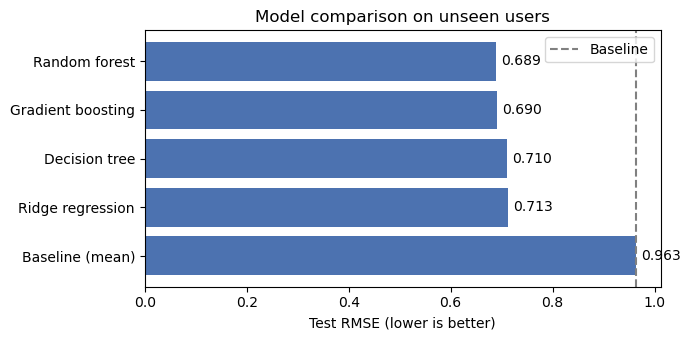

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.5))
order = results.sort_values("Test RMSE", ascending=False)
ax.barh(order["Model"], order["Test RMSE"], color="#4C72B0")
ax.axvline(results.loc[results["Model"] == "Baseline (mean)", "Test RMSE"].item(),
           color="grey", linestyle="--", label="Baseline")
for i, v in enumerate(order["Test RMSE"]):
    ax.text(v + 0.01, i, f"{v:.3f}", va="center")
ax.set_xlabel("Test RMSE (lower is better)")
ax.set_title("Model comparison on unseen users")
ax.legend()
plt.tight_layout()
plt.savefig("fig_model_comparison.png", dpi=150)
plt.show()

## 5. How one setting changes the score (decision tree depth)
A tree that is too shallow is too simple (**underfitting**). A tree that is too deep memorises the training users (**overfitting**).
The plot shows the training error and the cross-validation error for each depth (with `min_samples_leaf = 1`).

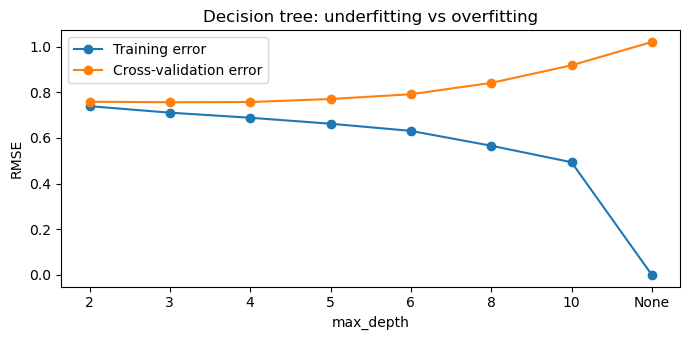

In [8]:
cvres = pd.DataFrame(searches["Decision tree"].cv_results_)
cvres = cvres[cvres["param_model__min_samples_leaf"] == 1].copy()
cvres["depth"] = cvres["param_model__max_depth"].apply(lambda d: "None" if pd.isna(d) else str(int(d)))
cvres["cv_rmse"] = -cvres["mean_test_score"]

# training error for the same depths
train_rmse = []
for d in cvres["param_model__max_depth"]:
    d = None if pd.isna(d) else int(d)
    p = Pipeline([("prep", make_preprocessor(NUMERIC_FEATURES, CATEGORICAL_FEATURES)),
                  ("model", DecisionTreeRegressor(max_depth=d, random_state=RANDOM_SEED))])
    p.fit(X_train, y_train)
    train_rmse.append(rmse(y_train, p.predict(X_train)))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(cvres["depth"], train_rmse, marker="o", label="Training error")
ax.plot(cvres["depth"], cvres["cv_rmse"], marker="o", label="Cross-validation error")
ax.set_xlabel("max_depth")
ax.set_ylabel("RMSE")
ax.set_title("Decision tree: underfitting vs overfitting")
ax.legend()
plt.tight_layout()
plt.savefig("fig_tree_depth.png", dpi=150)
plt.show()

## 6. Extra experiment: with the QoF columns (data leakage)
We train the best random forest again, but now **with** the 4 QoF columns.
If the error drops a lot, it confirms that QoF is almost the answer. This score is **not** a fair result, because QoF is not available when we want to predict MOS.

In [9]:
best_rf_params = {k.replace("model__", ""): v for k, v in searches["Random forest"].best_params_.items()}
leak_numeric = NUMERIC_FEATURES + LEAKAGE_FEATURES

leak_pipe = Pipeline([("prep", make_preprocessor(leak_numeric, CATEGORICAL_FEATURES)),
                      ("model", RandomForestRegressor(n_estimators=200, random_state=RANDOM_SEED,
                                                      n_jobs=-1, **best_rf_params))])
leak_pipe.fit(train[leak_numeric + CATEGORICAL_FEATURES], y_train)
y_pred_leak = leak_pipe.predict(test[leak_numeric + CATEGORICAL_FEATURES])

honest = results.loc[results["Model"] == "Random forest"].iloc[0]
leak_table = pd.DataFrame({
    "Random forest": ["without QoF (honest)", "with QoF (leakage)"],
    "Test RMSE": [honest["Test RMSE"], rmse(y_test, y_pred_leak)],
    "Test MAE": [honest["Test MAE"], mean_absolute_error(y_test, y_pred_leak)],
})
leak_table.round(3)

,Random forest,Test RMSE,Test MAE
0,without QoF (honest),0.689,0.473
1,with QoF (leakage),0.415,0.253


## 7. Which features matter most? (permutation importance)
Idea: take the best model, **shuffle one column** in the test set, and see how much the error grows.
If the error grows a lot, the model really needs this column. It is measured on the test users, so it shows what helps on new people.

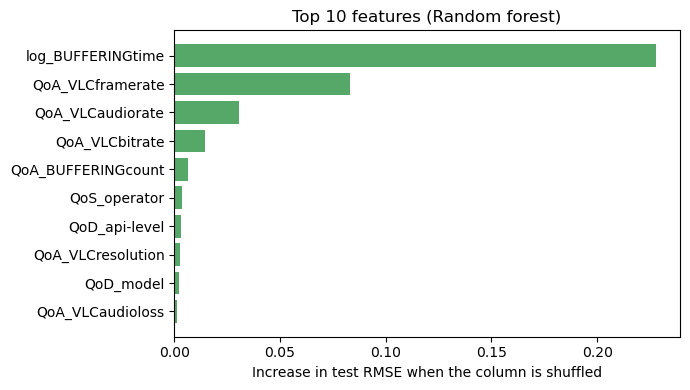

,Feature,RMSE increase
7,log_BUFFERINGtime,0.228
2,QoA_VLCframerate,0.083
4,QoA_VLCaudiorate,0.031
1,QoA_VLCbitrate,0.015
6,QoA_BUFFERINGcount,0.007
13,QoS_operator,0.004
8,QoD_api-level,0.003
0,QoA_VLCresolution,0.003
14,QoD_model,0.002
5,QoA_VLCaudioloss,0.001


In [10]:
best_name = results.loc[results["Model"] != "Baseline (mean)"].sort_values("Test RMSE").iloc[0]["Model"]
best_model = searches[best_name].best_estimator_

perm = permutation_importance(best_model, X_test, y_test, scoring="neg_root_mean_squared_error",
                              n_repeats=20, random_state=RANDOM_SEED, n_jobs=-1)
importance = (pd.DataFrame({"Feature": MAIN_FEATURES, "RMSE increase": perm.importances_mean})
              .sort_values("RMSE increase", ascending=False))

top = importance.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(top["Feature"], top["RMSE increase"], color="#55A868")
ax.set_xlabel("Increase in test RMSE when the column is shuffled")
ax.set_title(f"Top 10 features ({best_name})")
plt.tight_layout()
plt.savefig("fig_feature_importance.png", dpi=150)
plt.show()

importance.round(3)

## 8. Save the results

In [11]:
results.to_csv("results_models.csv", index=False)
leak_table.to_csv("results_leakage.csv", index=False)
importance.to_csv("results_importance.csv", index=False)
print("Saved: results_models.csv, results_leakage.csv, results_importance.csv and 3 figures (.png)")

Saved: results_models.csv, results_leakage.csv, results_importance.csv and 3 figures (.png)
